# Hospital Appointment No-Show Predictor
What patterns are associated with missed appointments, and how well can we predict a no-show at booking time?

In [ ]:
import io
from pathlib import Path

import pandas as pd
from google.colab import files

source_file = Path('KaggleV2-May-2016.csv')
if source_file.is_file():
    appointments = pd.read_csv(source_file)
else:
    uploaded = files.upload()
    filename = next(iter(uploaded))
    appointments = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f'Appointments: {len(appointments):,}')
print(f'Columns: {len(appointments.columns)}')
print(appointments['No-show'].value_counts(dropna=False))

Appointments: 110,527
Columns: 14
No-show
No     88208
Yes    22319
Name: count, dtype: int64


## Data quality checks

In [ ]:
booked = pd.to_datetime(appointments["ScheduledDay"], errors="coerce", utc=True)
visit = pd.to_datetime(appointments["AppointmentDay"], errors="coerce", utc=True)

# Compare calendar dates so a same-day booking counts as zero days.
lead_days = (visit.dt.normalize() - booked.dt.normalize()).dt.days

checks = pd.Series({
    "Missing appointment IDs": appointments["AppointmentID"].isna().sum(),
    "Duplicate appointment IDs": appointments["AppointmentID"].duplicated().sum(),
    "Missing or unexpected attendance labels": (~appointments["No-show"].isin(["Yes", "No"])).sum(),
    "Missing or unreadable booking dates": booked.isna().sum(),
    "Missing or unreadable appointment dates": visit.isna().sum(),
    "Appointments dated before booking": (lead_days < 0).sum(),
    "Appointments with a negative age": (appointments["Age"] < 0).sum(),
}, name="Flagged rows")

display(checks.to_frame())

,Flagged rows
Missing appointment IDs,0
Duplicate appointment IDs,0
Missing or unexpected attendance labels,0
Missing or unreadable booking dates,0
Missing or unreadable appointment dates,0
Appointments dated before booking,5
Appointments with a negative age,1


## Prepare the analysis dataset

Exclude appointments with a negative waiting time or a negative age. Keep same-day bookings and appointments recorded at age zero.

In [ ]:
flagged = (lead_days < 0) | (appointments["Age"] < 0)

appointments_clean = appointments.loc[~flagged].copy()
appointments_clean["lead_days"] = lead_days.loc[~flagged]
appointments_clean["no_show"] = appointments_clean["No-show"].map({"Yes": 1, "No": 0})

print(f"Rows excluded: {flagged.sum():,}")
print(f"Appointments retained: {len(appointments_clean):,}")
print(f"Missed appointments: {appointments_clean['no_show'].sum():,}")
print(f"No-show rate: {appointments_clean['no_show'].mean():.2%}")

Rows excluded: 6
Appointments retained: 110,521
Missed appointments: 22,314
No-show rate: 20.19%


## Does the no-show rate change with booking lead time?

In [ ]:
import pandas as pd

appointments_clean["wait_group"] = pd.cut(
    appointments_clean["lead_days"],
    bins=[-1, 0, 7, 14, 30, float("inf")],
    labels=["Same day", "1–7 days", "8–14 days", "15–30 days", "31+ days"]
)

wait_summary = (
    appointments_clean.groupby("wait_group", observed=True)["no_show"]
    .agg(appointments="size", missed="sum")
)

wait_summary["no_show_rate"] = wait_summary["missed"] / wait_summary["appointments"]

display(wait_summary.style.format({
    "appointments": "{:,}",
    "missed": "{:,}",
    "no_show_rate": "{:.2%}"
}))

,appointments,missed,no_show_rate
wait_group,,,
Same day,"38,562","1,792",4.65%
1–7 days,"32,185","7,772",24.15%
8–14 days,"12,025","3,664",30.47%
15–30 days,"17,371","5,661",32.59%
31+ days,"10,378","3,425",33.00%


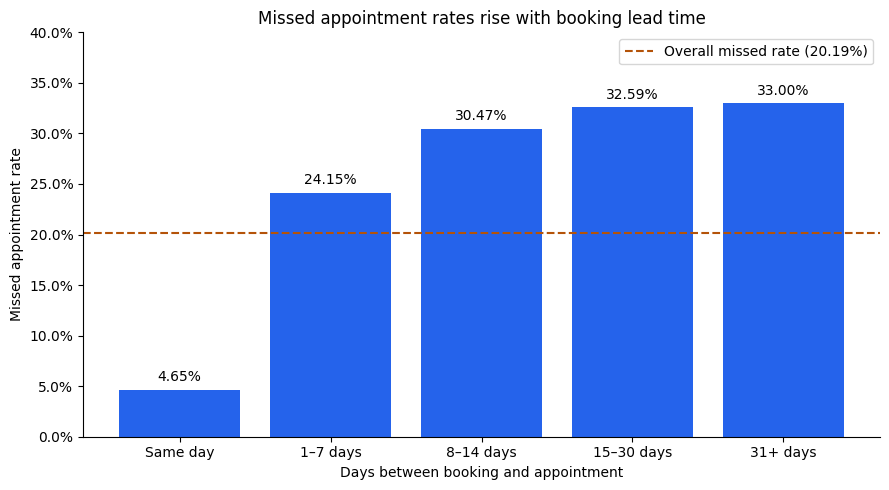

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    wait_summary.index.astype(str),
    wait_summary["no_show_rate"],
    color="#2563EB"
)

overall_rate = appointments_clean["no_show"].mean()

ax.axhline(
    overall_rate,
    color="#B45309",
    linestyle="--",
    label=f"Overall missed rate ({overall_rate:.2%})"
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2%}"
        for rate in wait_summary["no_show_rate"]
    ],
    padding=4
)

ax.set_title("Missed appointment rates rise with booking lead time")
ax.set_xlabel("Days between booking and appointment")
ax.set_ylabel("Missed appointment rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, 0.40)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()

Longer booking lead times were associated with higher no-show rates. Appointments booked 31 or more days ahead had the highest missed share (33.00%). The 1–7 day group accounted for the most missed appointments (7,772), because it had many more bookings.

## Does the no-show rate vary by age group?

In [ ]:
appointments_clean["age_group"] = pd.cut(
    appointments_clean["Age"],
    bins=[0, 13, 18, 25, 45, 65, float("inf")],
    labels=["0–12", "13–17", "18–24", "25–44", "45–64", "65+"],
    right=False
)

age_summary = (
    appointments_clean.groupby("age_group", observed=True)["no_show"]
    .agg(appointments="size", missed="sum", no_show_rate="mean")
)

display(age_summary.style.format({
    "appointments": "{:,}",
    "missed": "{:,}",
    "no_show_rate": "{:.2%}"
}))

,appointments,missed,no_show_rate
age_group,,,
0–12,"21,035","4,306",20.47%
13–17,"6,343","1,690",26.64%
18–24,"9,886","2,467",24.95%
25–44,"28,864","6,460",22.38%
45–64,"29,992","5,159",17.20%
65+,"14,401","2,232",15.50%


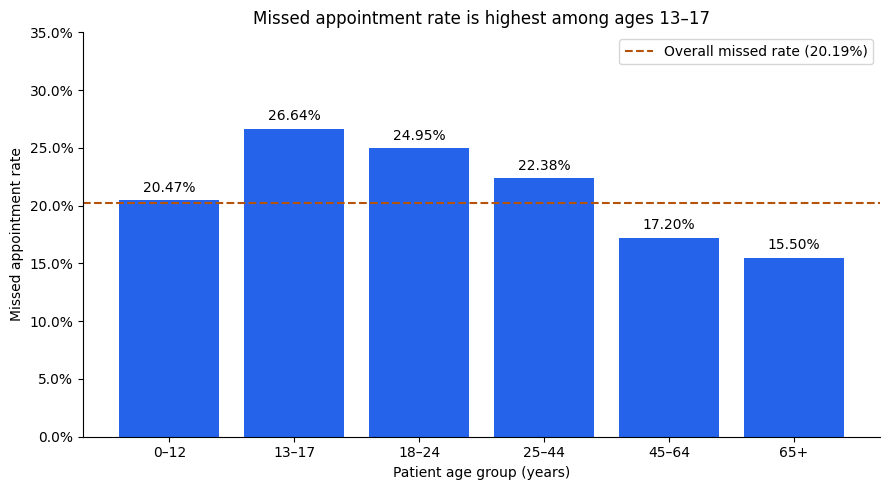

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    age_summary.index.astype(str),
    age_summary["no_show_rate"],
    color="#2563EB"
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2%}"
        for rate in age_summary["no_show_rate"]
    ],
    padding=4
)

ax.axhline(
    overall_rate,
    color="#B45309",
    linestyle="--",
    label=f"Overall missed rate ({overall_rate:.2%})"
)

ax.set_title("Missed appointment rate is highest among ages 13–17")
ax.set_xlabel("Patient age group (years)")
ax.set_ylabel("Missed appointment rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, 0.35)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()

Appointments for patients aged 13–17 had the highest no-show rate (26.64%). Rates decreased across successive older age groups, reaching 15.50% for patients aged 65+. Patients aged 25–44 accounted for the largest number of missed appointments (6,460). These comparisons describe associations within the dataset.

## How does attendance differ by recorded SMS status?

In [ ]:
sms_summary = (
    appointments_clean.groupby("SMS_received")["no_show"]
    .agg(
        appointments="size",
        missed="sum",
        no_show_rate="mean"
    )
    .rename(index={0: "No", 1: "Yes"})
    .rename(columns={
        "appointments": "Total appointments",
        "missed": "Missed appointments",
        "no_show_rate": "Missed appointment rate"
    })
)

sms_summary.index.name = "SMS reminder recorded?"

display(sms_summary.style.format({
    "Total appointments": "{:,}",
    "Missed appointments": "{:,}",
    "Missed appointment rate": "{:.2%}"
}))

,Total appointments,Missed appointments,Missed appointment rate
SMS reminder recorded?,,,
No,"75,039","12,530",16.70%
Yes,"35,482","9,784",27.57%


## SMS reminders and attendance within booking lead-time groups

Compare missed appointment rates for appointments with and without a
recorded SMS reminder within each waiting-time group.

In [ ]:
sms_by_wait = (
    appointments_clean
    .groupby(["wait_group", "SMS_received"], observed=True)["no_show"]
    .agg(
        appointments="size",
        missed="sum",
        no_show_rate="mean"
    )
    .reset_index()
)

sms_by_wait["SMS_received"] = sms_by_wait["SMS_received"].map({
    0: "No",
    1: "Yes"
})

sms_by_wait = sms_by_wait.rename(columns={
    "wait_group": "Booking lead time",
    "SMS_received": "SMS reminder recorded?",
    "appointments": "Total appointments",
    "missed": "Missed appointments",
    "no_show_rate": "Missed appointment rate"
})

display(
    sms_by_wait.style
    .hide(axis="index")
    .format({
        "Total appointments": "{:,}",
        "Missed appointments": "{:,}",
        "Missed appointment rate": "{:.2%}"
    })
)

Booking lead time,SMS reminder recorded?,Total appointments,Missed appointments,Missed appointment rate
Same day,No,"38,562","1,792",4.65%
1–7 days,No,"20,637","5,028",24.36%
1–7 days,Yes,"11,548","2,744",23.76%
8–14 days,No,"5,021","1,695",33.76%
8–14 days,Yes,"7,004","1,969",28.11%
15–30 days,No,"6,851","2,526",36.87%
15–30 days,Yes,"10,520","3,135",29.80%
31+ days,No,"3,968","1,489",37.53%
31+ days,Yes,"6,410","1,936",30.20%


In [ ]:
sms_rate_by_wait = (
    appointments_clean
    .groupby(["wait_group", "SMS_received"], observed=True)["no_show"]
    .mean()
    .unstack("SMS_received")
    .reindex(columns=[0, 1])
    .rename(columns={
        0: "No SMS recorded",
        1: "SMS recorded"
    })
)

sms_rate_by_wait.index.name = "Booking lead time"
sms_rate_by_wait.columns.name = None

display(
    sms_rate_by_wait.style.format(
        "{:.2%}",
        na_rep="No appointments"
    )
)

,No SMS recorded,SMS recorded
Booking lead time,,
Same day,4.65%,No appointments
1–7 days,24.36%,23.76%
8–14 days,33.76%,28.11%
15–30 days,36.87%,29.80%
31+ days,37.53%,30.20%


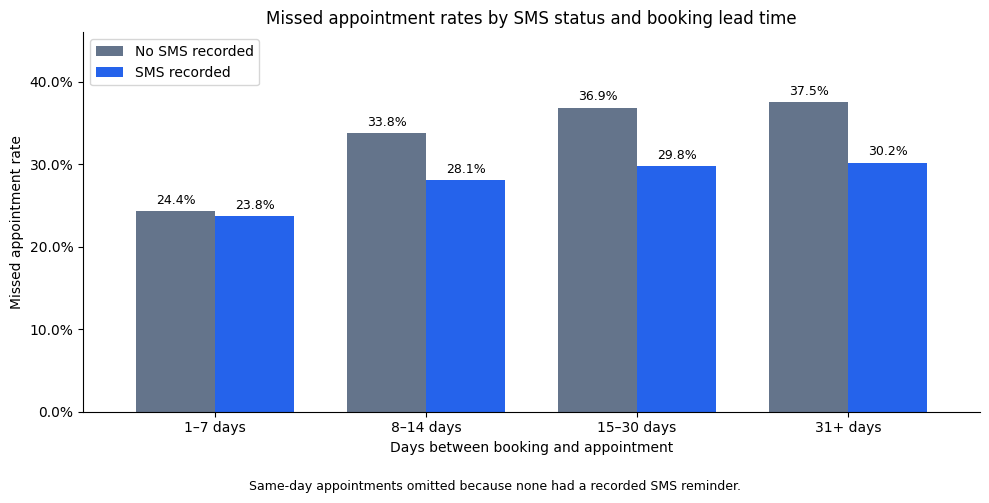

In [ ]:
sms_chart_data = (
    appointments_clean
    .groupby(["wait_group", "SMS_received"], observed=True)["no_show"]
    .mean()
    .unstack("SMS_received")
    .reindex(columns=[0, 1])
    .rename(columns={
        0: "No SMS recorded",
        1: "SMS recorded"
    })
    .dropna()
)

ax = sms_chart_data.plot.bar(
    figsize=(10, 5),
    color=["#64748B", "#2563EB"],
    width=0.75,
    rot=0
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_height():.1%}" for bar in container],
        padding=3,
        fontsize=9
    )

ax.set_title("Missed appointment rates by SMS status and booking lead time")
ax.set_xlabel("Days between booking and appointment")
ax.set_ylabel("Missed appointment rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, 0.46)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="")

plt.figtext(
    0.5, 0.01,
    "Same-day appointments omitted because none had a recorded SMS reminder.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

SMS reminders and missed appointments

Overall, appointments with a recorded SMS reminder had a higher missed appointment rate (27.57%) than those without one (16.70%). However, the groups differed in booking lead time.

The group without recorded reminders included 38,562 same-day appointments, whose missed rate was only 4.65%. These appointments lowered that group’s overall rate. There were no same-day appointments with a recorded SMS.

Within each of the four remaining waiting-time groups, appointments with a recorded SMS had a lower missed rate. For example, among appointments booked 31 or more days ahead, the rate was 30.20% with a recorded reminder and 37.53% without one.

These results show why booking lead time matters when comparing SMS groups. They establish an association, while the causal effect of reminders remains uncertain because reminder allocation and other differences between appointments could influence the results.

## Does attendance vary by appointment day of the week?

In [ ]:
appointments_clean["appointment_weekday"] = pd.to_datetime(
    appointments_clean["AppointmentDay"],
    utc=True
).dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    appointments_clean
    .groupby("appointment_weekday")["no_show"]
    .agg(
        appointments="size",
        missed="sum",
        no_show_rate="mean"
    )
    .reindex(weekday_order)
    .dropna(subset=["appointments"])
    .rename(columns={
        "appointments": "Total appointments",
        "missed": "Missed appointments",
        "no_show_rate": "Missed appointment rate"
    })
)

weekday_summary.index.name = "Appointment weekday"

display(weekday_summary.style.format({
    "Total appointments": "{:,.0f}",
    "Missed appointments": "{:,.0f}",
    "Missed appointment rate": "{:.2%}"
}))

,Total appointments,Missed appointments,Missed appointment rate
Appointment weekday,,,
Monday,"22,713","4,689",20.64%
Tuesday,"25,638","5,150",20.09%
Wednesday,"25,866","5,092",19.69%
Thursday,"17,246","3,337",19.35%
Friday,"19,019","4,037",21.23%
Saturday,39,9,23.08%


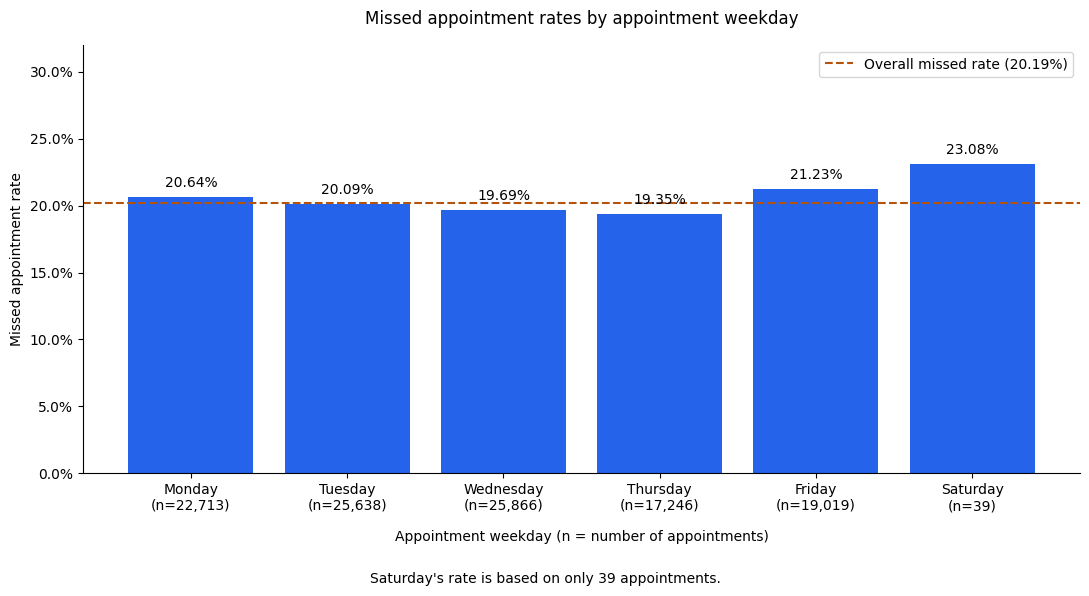

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

overall_rate = appointments_clean["no_show"].mean()

weekday_labels = [
    f"{day}\n(n={int(count):,})"
    for day, count in weekday_summary["Total appointments"].items()
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    weekday_labels,
    weekday_summary["Missed appointment rate"],
    color="#2563EB"
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2%}"
        for rate in weekday_summary["Missed appointment rate"]
    ],
    padding=5
)

ax.axhline(
    overall_rate,
    color="#B45309",
    linestyle="--",
    label=f"Overall missed rate ({overall_rate:.2%})"
)

ax.set_title(
    "Missed appointment rates by appointment weekday",
    pad=15
)
ax.set_xlabel(
    "Appointment weekday (n = number of appointments)",
    labelpad=12
)
ax.set_ylabel("Missed appointment rate")

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, 0.32)
ax.tick_params(axis="x", labelsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper right")

fig.text(
    0.5,
    0.02,
    "Saturday's rate is based on only 39 appointments.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

Missed appointment rates were relatively similar from Monday to Friday, ranging from 19.35% on Thursday to 21.23% on Friday—a difference of 1.88 percentage points. Tuesday recorded the largest number of missed appointments (5,150). Saturday’s rate was 23.08%, based on just 39 appointments, making it sensitive to small changes in counts. No Sunday appointments were recorded.

## How do missed appointment rates vary by neighbourhood?

In [ ]:
neighbourhood_summary = (
    appointments_clean
    .groupby("Neighbourhood")["no_show"]
    .agg(
        appointments="size",
        missed="sum",
        no_show_rate="mean"
    )
    .rename(columns={
        "appointments": "Total appointments",
        "missed": "Missed appointments",
        "no_show_rate": "Missed appointment rate"
    })
    .sort_values("Missed appointment rate", ascending=False)
)

neighbourhood_summary.index.name = "Neighbourhood"

display(neighbourhood_summary.style.format({
    "Total appointments": "{:,}",
    "Missed appointments": "{:,}",
    "Missed appointment rate": "{:.2%}"
}))

,Total appointments,Missed appointments,Missed appointment rate
Neighbourhood,,,
ILHAS OCEÂNICAS DE TRINDADE,2,2,100.00%
SANTOS DUMONT,"1,276",369,28.92%
SANTA CECÍLIA,448,123,27.46%
SANTA CLARA,506,134,26.48%
ITARARÉ,"3,514",923,26.27%
JESUS DE NAZARETH,"2,853",696,24.40%
HORTO,175,42,24.00%
ILHA DO PRÍNCIPE,"2,266",532,23.48%
CARATOÍRA,"2,565",591,23.04%


Missed appointment rates varied across neighbourhoods. Ilhas Oceânicas de Trindade recorded a 100% rate, based on only two appointments. Santos Dumont recorded 28.92% across 1,276 appointments, while Itararé recorded 26.27% across 3,514 appointments. Both exceeded the overall rate of 20.19%. These comparisons describe observed differences and require further analysis of factors such as age and booking lead time.

## Top 10 neighbourhoods by number of missed appointments

In [ ]:
most_missed_neighbourhoods = (
    neighbourhood_summary
    .sort_values("Missed appointments", ascending=False)
    .head(10)
)

display(most_missed_neighbourhoods.style.format({
    "Total appointments": "{:,}",
    "Missed appointments": "{:,}",
    "Missed appointment rate": "{:.2%}"
}))

,Total appointments,Missed appointments,Missed appointment rate
Neighbourhood,,,
JARDIM CAMBURI,"7,717","1,465",18.98%
MARIA ORTIZ,"5,805","1,219",21.00%
ITARARÉ,"3,514",923,26.27%
RESISTÊNCIA,"4,430",905,20.43%
CENTRO,"3,334",703,21.09%
JESUS DE NAZARETH,"2,853",696,24.40%
JARDIM DA PENHA,"3,877",631,16.28%
CARATOÍRA,"2,565",591,23.04%
TABUAZEIRO,"3,131",572,18.27%


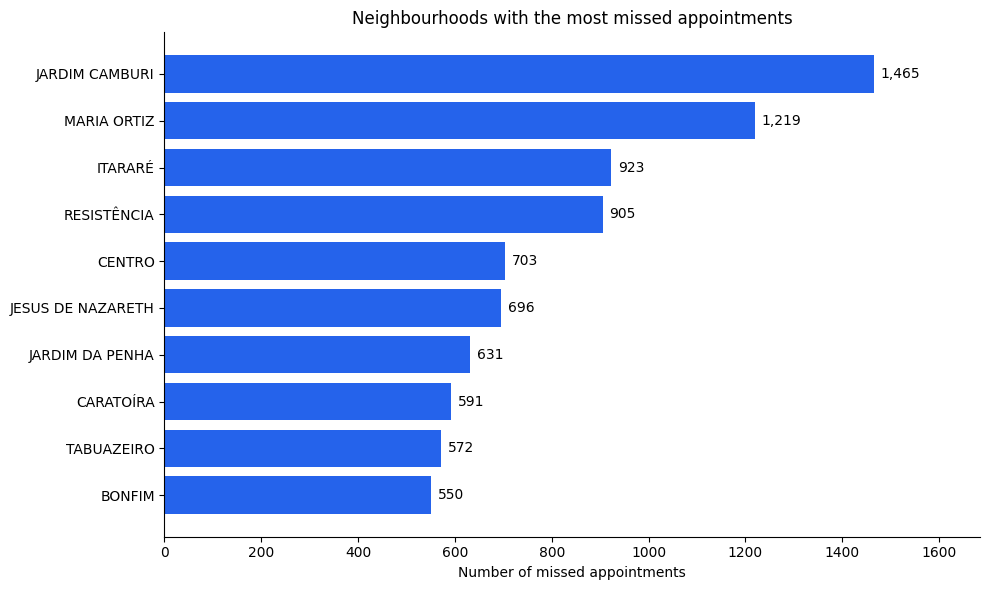

In [ ]:
neighbourhood_chart = most_missed_neighbourhoods.sort_values(
    "Missed appointments",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    neighbourhood_chart.index,
    neighbourhood_chart["Missed appointments"],
    color="#2563EB"
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,}"
        for count in neighbourhood_chart["Missed appointments"]
    ],
    padding=5
)

ax.set_title("Neighbourhoods with the most missed appointments")
ax.set_xlabel("Number of missed appointments")
ax.set_ylabel("")
ax.set_xlim(
    0,
    neighbourhood_chart["Missed appointments"].max() * 1.15
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Jardim Camburi recorded the most missed appointments (1,465), with a missed rate of 18.98%. Santos Dumont had a higher missed rate (28.92%) but fewer missed appointments (369). Appointment volume explains why the rankings by count and rate differ.

## Predicting missed appointments at booking time

In [ ]:
booking_features = [
    "age_group",
    "wait_group",
    "appointment_weekday",
    "Neighbourhood"
]

X = appointments_clean[booking_features].copy()
y = appointments_clean["no_show"].copy()

preview = X.head().rename(columns={
    "age_group": "Patient age group",
    "wait_group": "Booking lead time",
    "appointment_weekday": "Appointment weekday",
    "Neighbourhood": "Neighbourhood of appointment"
})
preview["Actual attendance"] = y.head().map({0: "Attended", 1: "Missed"})

print(f"Appointments ready for modelling: {len(X):,}")
print(f"Booking-time inputs per appointment: {X.shape[1]}")
display(preview.style.hide(axis="index"))

Appointments ready for modelling: 110,521
Booking-time inputs per appointment: 4


Patient age group,Booking lead time,Appointment weekday,Neighbourhood of appointment,Actual attendance
45–64,Same day,Friday,JARDIM DA PENHA,Attended
45–64,Same day,Friday,JARDIM DA PENHA,Attended
45–64,Same day,Friday,MATA DA PRAIA,Attended
0–12,Same day,Friday,PONTAL DE CAMBURI,Attended
45–64,Same day,Friday,JARDIM DA PENHA,Attended


Each row represents one appointment. The table shows the first five of 110,521 appointments. The first four columns contain information available at booking. The final column shows what happened afterward. Rows 1 and 2 look the same because separate appointments can share all four booking details and the same outcome. All five appointments in this preview were attended. Across the full dataset, 22,314 appointments were missed (20.19%).




In [ ]:
import pandas as pd

# Use calendar dates so all bookings on the cutoff day stay together.
booking_date = pd.to_datetime(
    appointments_clean["ScheduledDay"], utc=True
).dt.normalize()

visit_date = pd.to_datetime(
    appointments_clean["AppointmentDay"], utc=True
).dt.normalize()

cutoff = booking_date.quantile(0.80, interpolation="lower")

# At the start of the cutoff day, only earlier visits have known outcomes.
train_rows = (booking_date < cutoff) & (visit_date < cutoff)
pending_rows = (booking_date < cutoff) & (visit_date >= cutoff)
test_rows = booking_date >= cutoff

X_train, y_train = X.loc[train_rows].copy(), y.loc[train_rows].copy()
X_test, y_test = X.loc[test_rows].copy(), y.loc[test_rows].copy()

split_summary = pd.DataFrame({
    "Group": ["Training", "Pending at cutoff", "Testing"],
    "Which appointments?": [
        "Booked and completed before the cutoff",
        "Booked earlier, with the visit due on or after the cutoff",
        "Booked on or after the cutoff",
    ],
    "Appointments": [train_rows.sum(), pending_rows.sum(), test_rows.sum()],
})

assert split_summary["Appointments"].sum() == len(appointments_clean)

print(f"Cutoff date: {cutoff:%d %B %Y}")
display(split_summary.style.hide(axis="index").format({"Appointments": "{:,}"}))

Cutoff date: 25 May 2016


Group,Which appointments?,Appointments
Training,Booked and completed before the cutoff,"71,369"
Pending at cutoff,"Booked earlier, with the visit due on or after the cutoff","16,187"
Testing,Booked on or after the cutoff,"22,965"


We train the model using earlier bookings whose attendance outcome was already known by the cutoff. We then test it on later bookings to see how well it predicts missed appointments. We set aside appointments that were already booked but still pending at the cutoff. This lets us evaluate the model using only the information the hospital would have had at the time.
We selected the cutoff using the 80th percentile of booking dates, then reserved all appointments booked on or after that day to test how well the model predicts attendance for later bookings.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Turn booking details such as "Friday" and "Same day" into numeric inputs.
booking_inputs = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), X_train.columns.tolist())
])

no_show_model = Pipeline([
    ("prepare_inputs", booking_inputs),
    ("predict_no_show", LogisticRegression(max_iter=1000))
])

# Learn from earlier appointments whose attendance was known at the cutoff.
no_show_model.fit(X_train, y_train)

# Class 1 means "Missed". Select its probability for each later booking.
missed_column = no_show_model.classes_.tolist().index(1)
test_missed_probability = no_show_model.predict_proba(X_test)[:, missed_column]

# Show five predictions with plain-language labels.
prediction_preview = X_test.head().rename(columns={
    "age_group": "Patient age group",
    "wait_group": "Booking lead time",
    "appointment_weekday": "Appointment weekday",
    "Neighbourhood": "Neighbourhood of appointment"
}).copy()

prediction_preview["Estimated chance of missing"] = test_missed_probability[:5]

print(f"Earlier appointments used for training: {len(X_train):,}")
print(f"Later bookings scored: {len(X_test):,}")
display(
    prediction_preview.style
    .hide(axis="index")
    .format({"Estimated chance of missing": "{:.1%}"})
)

Earlier appointments used for training: 71,369
Later bookings scored: 22,965


Patient age group,Booking lead time,Appointment weekday,Neighbourhood of appointment,Estimated chance of missing
25–44,1–7 days,Tuesday,MARIA ORTIZ,28.8%
45–64,Same day,Tuesday,MARIA ORTIZ,4.0%
18–24,1–7 days,Tuesday,MARIA ORTIZ,32.2%
25–44,Same day,Tuesday,MARIA ORTIZ,5.6%
45–64,Same day,Monday,MARIA ORTIZ,4.2%


We trained the model on 71,369 earlier appointments and used it to estimate the chance of a missed visit for 22,965 later bookings. The model used four details available at booking time: age group, booking lead time, appointment weekday, and neighbourhood. The first five bookings shown are all in Maria Ortiz. Compare rows 1 and 4: both were Tuesday appointments for patients aged 25–44, but the estimated chance of a missed visit was 28.8% for the booking made 1–7 days ahead and 5.6% for the same-day booking.

## Did higher-scored appointments get missed more often?

In [ ]:
import pandas as pd

# Pair each booking's predicted chance with its actual attendance outcome.
evaluation = pd.DataFrame({
    "Estimated chance": test_missed_probability,
    "Actually missed": y_test.to_numpy()
})

# Group bookings by the chance estimated by the model.
evaluation["Estimated chance of missing"] = pd.cut(
    evaluation["Estimated chance"],
    bins=[0, 0.10, 0.20, 0.30, float("inf")],
    labels=["Under 10%", "10% to under 20%", "20% to under 30%", "30% or higher"],
    right=False
)

risk_summary = (
    evaluation.groupby("Estimated chance of missing", observed=True)
    .agg(
        bookings=("Actually missed", "size"),
        missed=("Actually missed", "sum"),
        predicted_rate=("Estimated chance", "mean"),
        actual_rate=("Actually missed", "mean")
    )
    .rename(columns={
        "bookings": "Total bookings",
        "missed": "Missed appointments",
        "predicted_rate": "Average predicted chance",
        "actual_rate": "Actual missed rate"
    })
)

print(f"Overall missed rate in the test bookings: {y_test.mean():.2%}")

display(risk_summary.style.format({
    "Total bookings": "{:,}",
    "Missed appointments": "{:,}",
    "Average predicted chance": "{:.2%}",
    "Actual missed rate": "{:.2%}"
}))

Overall missed rate in the test bookings: 11.84%


,Total bookings,Missed appointments,Average predicted chance,Actual missed rate
Estimated chance of missing,,,,
Under 10%,"13,549",555,4.95%,4.10%
10% to under 20%,"2,175",395,17.51%,18.16%
20% to under 30%,"5,157","1,151",24.89%,22.32%
30% or higher,"2,084",617,34.25%,29.61%


Across 22,965 later bookings, 11.84% of appointments were missed. The actual missed rate increased across all four prediction groups, from 4.10% in the lowest group to 29.61% in the highest. The model successfully ranked these groups by their likelihood of a missed visit. Its largest gap was in the highest group, where it predicted 34.25% on average and observed attendance records showed 29.61% were missed.

The 30%-or-higher group had the highest missed rate (29.61%). The 20%-to-under-30% group accounted for the most missed visits (1,151) because it contained more bookings.

In [ ]:
total_missed = evaluation["Actually missed"].sum()
results = []

for risk_threshold in [0.30, 0.20]:
    flagged_bookings = evaluation.loc[evaluation["Estimated chance"] >= risk_threshold]
    missed = flagged_bookings["Actually missed"].sum()

    results.append({
        "Flag bookings scoring": f"{risk_threshold:.0%} or higher",
        "Bookings flagged": len(flagged_bookings),
        "Actual misses among flagged": missed,
        "Missed rate among flagged": missed / len(flagged_bookings),
        "Share of all misses flagged": missed / total_missed
    })

comparison = pd.DataFrame(results)

display(comparison.style.hide(axis="index").format({
    "Bookings flagged": "{:,}",
    "Actual misses among flagged": "{:,}",
    "Missed rate among flagged": "{:.2%}",
    "Share of all misses flagged": "{:.2%}"
}))

Flag bookings scoring,Bookings flagged,Actual misses among flagged,Missed rate among flagged,Share of all misses flagged
30% or higher,"2,084",617,29.61%,22.70%
20% or higher,"7,241","1,768",24.42%,65.05%


With a 20% cutoff, the model flagged 7,241 bookings. Of those, 1,768 were actually missed, so about 24 in every 100 flagged bookings ended in a missed visit. Those same 1,768 appointments accounted for 65.05% of all 2,718 missed visits in the test set. Raising the cutoff to 30% produced a shorter list of 2,084 bookings. About 30 in every 100 bookings on that list were missed, and the list captured 22.70% of all missed visits.

In [ ]:
test_missed_rate = evaluation["Actually missed"].mean()

baseline_check = comparison[
    ["Flag bookings scoring", "Missed rate among flagged"]
].copy()

baseline_check["Overall test missed rate"] = test_missed_rate
baseline_check["Times the overall rate"] = (
    baseline_check["Missed rate among flagged"] / test_missed_rate
)

display(baseline_check.style.hide(axis="index").format({
    "Missed rate among flagged": "{:.2%}",
    "Overall test missed rate": "{:.2%}",
    "Times the overall rate": "{:.2f}×"
}))

Flag bookings scoring,Missed rate among flagged,Overall test missed rate,Times the overall rate
30% or higher,29.61%,11.84%,2.50×
20% or higher,24.42%,11.84%,2.06×


Across the test set, about 12 in every 100 bookings were missed. That rose to 24 in every 100 among bookings flagged at the 20% cutoff and 30 in every 100 at the 30% cutoff. Both rules identified groups with an above-average missed rate. The 30% cutoff produced the more concentrated list, while the 20% cutoff captured more missed visits overall.

## Conclusion

Of the 110,521 appointments in the cleaned dataset, 22,314 were missed (20.19%). Booking lead time showed a clear pattern. Patients missed 4.65% of same-day appointments and 33.00% of appointments booked at least 31 days ahead.

Using four details available at booking — age group, booking lead time, appointment weekday, and neighbourhood — the model estimated the chance of a missed visit. Across the 22,965 later bookings used for testing, 11.84% were missed. The actual missed rate rose across all four prediction groups, from 4.10% in the lowest group to 29.61% in the highest.

The choice of cutoff depends on the clinic’s goal. A 30% cutoff produced a shorter list of 2,084 bookings, with about 30 missed visits per 100 flagged. A 20% cutoff produced a longer list of 7,241 bookings and captured about 65 of every 100 missed visits in the test set. A clinic could use this comparison to plan reminder calls. Measuring how many missed visits those calls would prevent would require a separate evaluation.

## Predict a new appointment

Try the predictor on a new booking

Choose an age group, booking lead time, day of visit, and appointment neighbourhood. The model will estimate the chance that the appointment is missed. To explore how one detail influences the estimate, change one dropdown at a time.

In [ ]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display

def booking_dropdown(column, label):
    values = X_train[column].dropna()
    if isinstance(values.dtype, pd.CategoricalDtype):
        options = values.cat.remove_unused_categories().cat.categories.tolist()
    else:
        options = sorted(values.unique())

    return widgets.Dropdown(
        options=options,
        description=label,
        style={"description_width": "initial"}
    )

def predict_booking(age_group, wait_group, appointment_weekday, neighbourhood):
    new_booking = pd.DataFrame([{
        "age_group": age_group,
        "wait_group": wait_group,
        "appointment_weekday": appointment_weekday,
        "Neighbourhood": neighbourhood
    }])

    missed_column = no_show_model.classes_.tolist().index(1)
    probability = no_show_model.predict_proba(new_booking)[0, missed_column]
    print(f"Estimated chance of missing this appointment: {probability:.1%}")

controls = {
    "age_group": booking_dropdown("age_group", "Patient age group"),
    "wait_group": booking_dropdown("wait_group", "Time from booking to visit"),
    "appointment_weekday": booking_dropdown("appointment_weekday", "Day of visit"),
    "neighbourhood": booking_dropdown("Neighbourhood", "Appointment neighbourhood")
}

result = widgets.interactive_output(predict_booking, controls)
display(widgets.VBox([*controls.values(), result]))